## Abstract

We introduced a helix penalty that shifted ESMFold2 binder designs toward β-rich structures across five targets. Although confidence scores fell on average, more designs met our criteria for both sheet content and confidence. The shift began within the first few optimization steps, even though the amino-acid probabilities remained close to uniform.

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
AI assistance was used to review the analysis and revise this draft. The author-approved disclosure will be added before publication.
:::

## Purpose

We wanted to make ESMFold2 produce more β-rich binder candidates without retraining the model. Its unmodified design procedure returned mostly helical structures in our campaigns, which limited the secondary-structure compositions available for screening.

We added a penalty for helix-like geometry and measured its effects across five targets. Tracking helicity alongside sequence entropy showed that the predictions diverged while the amino-acid distributions remained nearly uniform.

## Introduction

ESMFold2 is a structure prediction model that uses representations from the ESMC protein language model to predict proteins and their complexes. Alongside the model, @candido2026language present a binder-design algorithm that combines structural feedback from ESMFold2 with sequence feedback from ESMC. Starting from a soft sequence — a probability distribution over amino acids at each position — the algorithm repeatedly predicts the binder–target complex, evaluates a design objective, and updates the candidate sequence. As optimization proceeds, the algorithm progressively hardens the soft sequence into a discrete amino-acid sequence. The weights of both ESMC and ESMFold2 remain frozen, allowing researchers to design proteins under different objectives without retraining or fine-tuning either model. This approach builds on earlier work in protein hallucination and gradient-based sequence optimization [@anishchenko2021hallucination; @norn2021landscape; @frank2024relaxed], and was popularized for binder design by BindCraft [@pacesa2025bindcraft].

Although training data, model architectures, design objectives, and filtering choices differ among methods, several binder-design workflows favor α-helical designs. BindCraft reports this tendency in its confidence-driven designs [@pacesa2025bindcraft], and RFdiffusion's developers note that the default model often generates predominantly helical binders [@rosettacommons2025rfdiffusiondocs]. A separate 10-target benchmark reports high helix content among RFdiffusion designs passing its computational screen, while PXDesign-d produces a broader range of helix fractions [@protenix2025pxdesign]. We observed a similar enrichment in unsteered ESMFold2 designs, which led us to investigate how we could change this preference.

Reducing this preference has several potential benefits: bringing designed secondary-structure compositions closer to those of natural binding proteins, increasing structural diversity within a campaign, and reaching binding sites that favor different interface geometries. The last motivation has experimental support. Guiding RFdiffusion toward β-strand pairing produced binders to exposed sheet edges, including on ALK-3 and KIT, where earlier design campaigns had failed [@sappington2026betapairing]. Such results motivate exploring alternatives to predominantly helical designs.

BindCraft already uses a helicity loss to obtain β-rich designs, with a decrease in computational screening success [@pacesa2025bindcraft]. To our knowledge, secondary-structure steering with a helicity penalty has not been demonstrated for ESMFold2. Understanding where the preference arises could also reveal other ways to intervene: a helical final design may reflect a preference already present in the initial prediction, its reinforcement during sequence optimization, or both.

Here, we investigated how to redirect ESMFold2's helix preference and what that cost in predicted confidence. We varied the strength of a helicity penalty across targets and tracked how the predictions changed as the soft sequence became more concentrated. The penalty increased sheet content and the number of candidates passing a combined sheet-content and confidence screen, despite lowering average confidence. Helicity diverged early while sequence entropy remained near its maximum.

:::{.callout-note collapse="true" title="Computation and reproducibility"}

Running the notebook downloads archived model structures, scores, traces, and natural-reference inputs from [Zenodo](https://doi.org/10.5281/zenodo.23542792) as needed, then recalculates measurements. This repository includes target inputs and the generation code.

You can generate new designs using `python -m analysis.campaign` after deploying the Modal workers. Runs on graphics processing units (GPUs) cost compute and aren't seed-reproducible, so new runs are new samples rather than replacements for the reported designs. See the [setup guide](pages/SETUP.qmd) for input locations and commands.

:::

In [ ]:
# | include: false

import warnings

import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)

In [ ]:
# | include: false
from analysis import (
    artifacts,
    composition,
    deposit,
    figures,
    loss_trace,
    paths,
    reference,
    targets,
)

paths.ensure_dirs()
if any(not artifacts.status(t, a).is_analysable for t, a in targets.publication_campaigns()):
    deposit.DESIGN_TABLES.fetch()

## Unsteered designs are helix-rich relative to natural proteins

We generated 30 unsteered binders per target using the five constructs from the ESMFold2 paper [@candido2026language] (@tbl-targets). We sampled binder lengths from a 60–200-residue range.

| Target | Target region | UniProt accession | UniProt residues | Target length (residues) |
|---|---|---|---|---:|
| EGFR | Domain III | [P00533](https://www.uniprot.org/uniprotkb/P00533/entry) | 334–524 | 191 |
| PDGFRβ | Domains D2–D3 | [P09619](https://www.uniprot.org/uniprotkb/P09619/entry) | 126–312 | 187 |
| PD-L1 | IgV domain | [Q9NZQ7](https://www.uniprot.org/uniprotkb/Q9NZQ7/entry) | 18–132 | 115 |
| CTLA-4 | IgV domain | [P16410](https://www.uniprot.org/uniprotkb/P16410/entry) | 38–155 | 118 |
| CD45 | Domains d3–d4 | [P08575](https://www.uniprot.org/uniprotkb/P08575/entry) | 390–574 | 185 |

: Human target constructs from Table S10 of @candido2026language. Residue ranges use canonical UniProt numbering and include both endpoints. EGFR, epidermal growth factor receptor; PDGFRβ, platelet-derived growth factor receptor β; PD-L1, programmed death-ligand 1; CTLA-4, cytotoxic T-lymphocyte-associated protein 4; CD45, cluster of differentiation 45; IgV, immunoglobulin variable-like. {#tbl-targets}

To compare their secondary-structure composition with binders found in nature, we queried the Research Collaboratory for Structural Bioinformatics (RCSB) Protein Data Bank (PDB) for experimentally resolved complexes containing two distinct protein entities and selected chains within the same 60–200-residue range. We refer to each selected chain as the natural binder and the other as its partner.

We then compared the helix, sheet, and loop fractions of the two groups within five binder-length bins (@fig-composition).

:::{.callout-note collapse="true" title="Natural protein baseline construction"}

We selected X-ray structures containing two distinct protein entities and a binder with a named source organism other than "synthetic construct," retaining one representative per sequence-identity cluster. We excluded records annotated as designed proteins and chains outside the length range or with insufficient resolved backbone. The code below recalculates measurements from archived RCSB inputs and applies these selection criteria. We flagged small interfaces and peptide partners but retained them.

We measured natural and designed chains with PyDSSP (v0.9.1), using the same backbone-based helix, sheet, and loop assignments [@minami2024pydssp]. For designs, we measured the final binder structures predicted by the primary ESMFold2 critic, the model used for evaluation. Only residues with N, Cα, C, and O coordinates contribute to the fractions.

In [ ]:
# | code-fold: true
# | code-summary: "Measure and select the natural protein reference"

reference_pairs = reference.pairs()
eligible = (
    reference_pairs["cluster_representative"].eq(1)
    & reference_pairs["measured"].eq(1)
    & reference_pairs["binder_design_like"].eq(0)
    & reference_pairs["excluded_short_or_long"].eq(0)
    & reference_pairs["excluded_incomplete"].eq(0)
)
natural = reference_pairs.loc[eligible].reset_index(drop=True)

for setting, value in reference.recorded_query_settings().items():
    print(f"{setting}: {value}")
print(f"Retained reference: {len(natural):,} chains from {natural.pdb_id.nunique():,} PDB entries")
print(f"  Small-interface flag: {int(natural.flag_small_interface.sum()):,} chains")
print(f"  Peptide-partner flag: {int(natural.flag_peptide_target.sum()):,} chains")

using the recorded search results in natural_binder_search_hits.json, snapshot 2026-09-02
downloading 2385 mmCIF files...
  downloaded 200/2385
  downloaded 400/2385
  downloaded 600/2385
  downloaded 800/2385
  downloaded 1000/2385
  downloaded 1200/2385
  downloaded 1400/2385
  downloaded 1600/2385
  downloaded 1800/2385
  downloaded 2000/2385
  downloaded 2200/2385
measuring 2385 entries...
  measured 200 entries (20 failures)
  measured 400 entries (35 failures)
  measured 600 entries (51 failures)
  measured 800 entries (61 failures)
  measured 1000 entries (87 failures)
  measured 1200 entries (104 failures)
  measured 1400 entries (128 failures)
  measured 1600 entries (146 failures)
  measured 1800 entries (160 failures)
  measured 2000 entries (173 failures)
  measured 2200 entries (189 failures)
{
  "snapshot_release_date": "2026-09-02",
  "in_range_entities": 10601,
  "in_range_entries": 8319,
  "clusters": 2790,
  "cluster_representatives": 2790,
  "measured": 2592,
  "excl

:::

In [ ]:
# | code-fold: true
# | code-summary: "Measure unsteered binder composition for each target"

TARGETS = list(targets.TARGET_SPECS)
campaign_composition = {}
for target in TARGETS:
    campaign_composition[target, "vanilla"] = composition.measure_campaign(target, "vanilla")

designs = pd.concat(campaign_composition.values(), ignore_index=True)

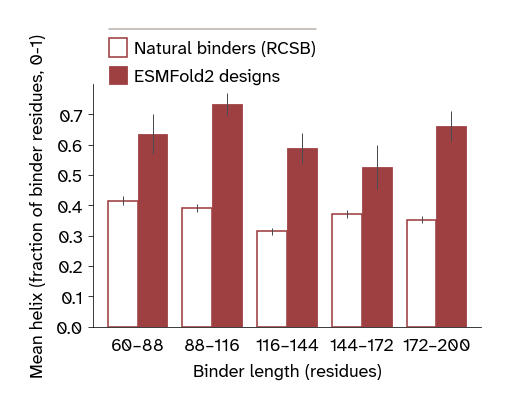

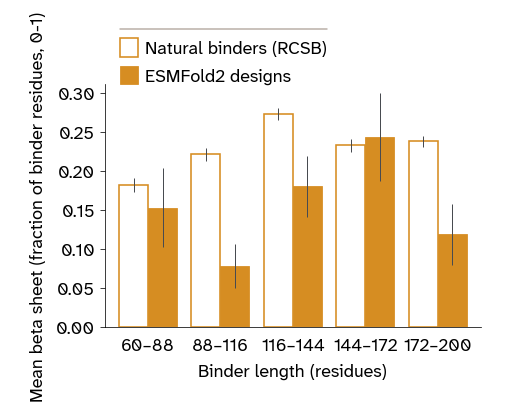

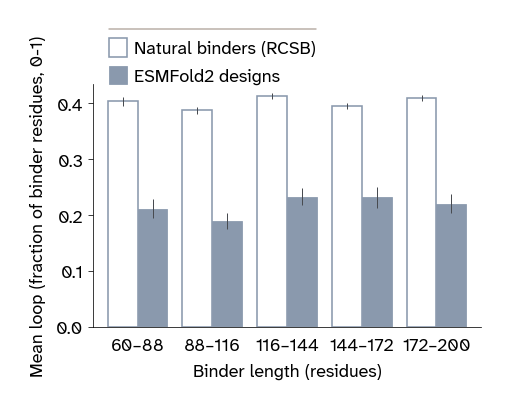

In [ ]:
# | label: fig-composition
# | fig-cap: "Secondary-structure composition of unsteered designs and the experimental reference, grouped into five binder-length bins. Unfilled bars show the natural reference from the Research Collaboratory for Structural Bioinformatics (RCSB) Protein Data Bank; filled bars show designs. Each chain contributes once to its bin. Bars are means; whiskers are standard errors across chains. Panel y-axes differ."
# | fig-subcap:
# |   - "Helix"
# |   - "β-sheet"
# |   - "Loop"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Compare chain means and standard errors within five length bins"

import numpy as np
from matplotlib import pyplot as plt

length_edges = np.linspace(60, 200, 6)
length_summaries = {}
for state, columns in figures.STATES.items():
    reference_summary = composition.summarize_by_length(
        natural[columns.natural_column], natural["binder_sample_length_residues"], length_edges
    )
    design_summary = composition.summarize_by_length(
        designs[columns.design_column], designs["binder length (residues)"], length_edges
    )
    length_summaries[state] = {"natural": reference_summary, "designs": design_summary}
    figures.composition_comparison(reference_summary, design_summary, state, length_edges)

Unsteered ESMFold2 designs are substantially more helical than the natural reference, with correspondingly less sheet and loop (@fig-composition). This pattern recurs across binder lengths and all five targets, suggesting a persistent preference in the design workflow. Redirecting that preference could help a design campaign explore more of the secondary-structure compositions found among natural binding partners.

## A helix penalty changes the design objective

The reference comparison suggests a practical opportunity: reduce the predominance of helices so that a campaign samples more of the sheet-containing compositions found in natural complexes. To test this, we added a term to the existing objective that penalizes helix-like geometry.

### The existing structural objective

The default structural loss combines intrabinder contacts, contacts between the target and binder, and a size-dependent compactness term:

$$
\mathcal{L}_{\mathrm{struct}}
= 0.5\,\mathcal{L}_{\mathrm{intra}}
+ 0.5\,\mathcal{L}_{\mathrm{inter}}
+ 0.2\,\mathcal{L}_{\mathrm{glob}}.
$$

The intrabinder term favors nonlocal contacts within the binder. The interface term asks each target residue for a contact with the binder, and the compactness term favors smaller predicted binder dimensions. For details, see @candido2026language.

### Penalizing helix-like distances

We use a local geometric feature of an α-helix: Residues four positions apart have nearby Cα atoms. The distogram gives the predicted probability distribution over residue-pair distances. For each eligible binder position, we sum the probability below 7 Å and average over positions:

$$
\mathcal{L}_{\mathrm{helix}}=\frac{1}{L-4}\sum_{i=1}^{L-4}
P(d_{i,i+4}<7\ \text{Å})\in[0,1].
$$

We excluded the final four residues from the average because they have no partner at this offset. The penalty acts only on the binder block of the distogram.

To steer sequence optimization, we replace the default structural objective $\mathcal{L}_{\mathrm{struct}}$ with an objective that includes the weighted helicity penalty:

$$
\mathcal{L}^{\prime}_{\mathrm{struct}}
=\mathcal{L}_{\mathrm{struct}}+w\,\mathcal{L}_{\mathrm{helix}}.
$$

Increasing the weight $w$ makes these short $i,i+4$ distances more costly.

The term $\mathcal{L}_{\mathrm{helix}}$ is a differentiable proxy, not a secondary-structure assignment. A low value doesn't distinguish a β-strand from an irregular extended segment, and it doesn't specify how strands should pair. We therefore evaluate the resulting structures separately with PyDSSP. @fig-scene illustrates the distance criterion on an example protein.

:::{.callout-note collapse="true" title="Relationship to BindCraft's helicity loss"}

We developed this formulation before becoming aware of BindCraft's helicity loss [@pacesa2025bindcraft]. Both use the same underlying strategy of steering secondary structure by discouraging short intrabinder distances characteristic of helices. BindCraft's [implementation](https://github.com/martinpacesa/BindCraft/blob/7cd4ace1b7407adf66a50dfefa47de2270f5e4a9/functions/colabdesign_utils.py) averages a [negative-log contact probability](https://github.com/sokrypton/ColabDesign/blob/24a449493c9e60fc8fefd4981a4b83f7900b9110/colabdesign/af/loss.py) for binder residue pairs separated by three positions, using a 6 Å cutoff. Our formulation averages contact probabilities for pairs separated by four positions, using a 7 Å cutoff. We haven't made a direct comparison of the two formulations under matched conditions.
:::

In [ ]:
# | label: fig-scene
# | fig-cap: "A predicted binder colored by the coordinate-based distance criterion underlying the penalty. Red marks a Cα pair at positions $i$ and $i+4$ below 7 Å; each such pair contributes $1/(L-4)$ to the binary coordinate average. The last four residues are unscored. Hovering shows the measured pair and distance. The optimized loss uses distogram probabilities rather than measured coordinate distances."
# | code-fold: true
# | code-summary: "Inspect the distance criterion for residue pairs four positions apart"

from analysis import scene

scene.loss_term_scene(paths.ASSETS / "example-complex.pdb").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Increasing the weight replaces helix with sheet and loop

We compared weights of 0, 0.5, 1.0, 2.0, and 5.0, with 30 seeds per condition on each target. @fig-scan-1 shows the mean composition pooled across all five targets; @fig-scan-2 shows the pooled distribution of helix fractions.

In [ ]:
# | code-fold: true
# | code-summary: "Measure the target-by-weight comparison, with 30 designs per condition"

ARMS = list(targets.CAMPAIGN_ARMS)
for target in TARGETS:
    for arm in ARMS:
        if (target, arm) not in campaign_composition:
            campaign_composition[target, arm] = composition.measure_campaign(target, arm)

steered = pd.concat(campaign_composition.values(), ignore_index=True)
campaign_sizes = steered.groupby(["target", "arm"]).size()
assert campaign_sizes.eq(targets.N_SEEDS).all()

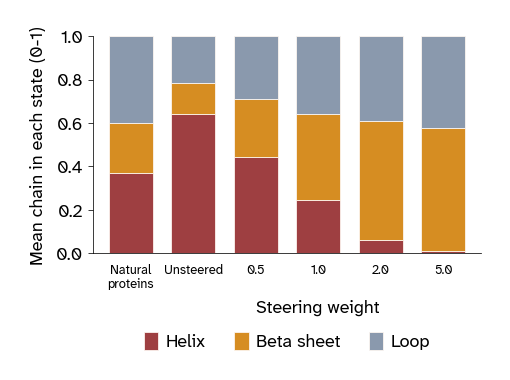

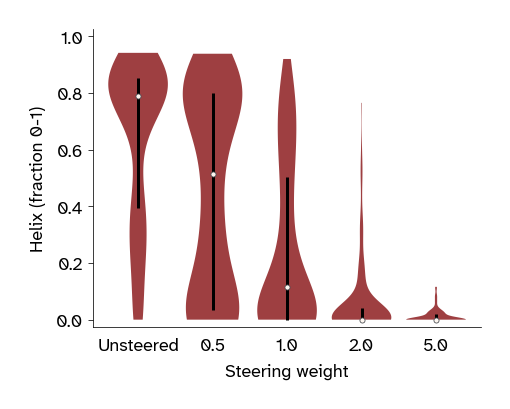

In [ ]:
# | label: fig-scan
# | fig-cap: "Secondary-structure composition across steering weights. The stacked bars pool all five targets, with 150 designs per weight and equal contributions from each target; the reference includes all natural chains without resampling or weighting. The violins show smoothed helix-fraction distributions for the same 150 designs per weight, restricted to each group’s observed range and scaled to equal maximum width. White dots mark medians; thick vertical lines span the interquartile range. PyDSSP assigns secondary structure from backbone coordinates: final complexes predicted by the primary critic for designs, and experimental structures for the natural reference."
# | fig-subcap:
# |   - "Mean PyDSSP helix, sheet, and loop fractions from final predicted binder structures across all five targets (150 designs per weight). The natural reference uses PyDSSP assignments from experimental structures."
# |   - "Distribution of PyDSSP helix fractions from final predicted binder structures across all five targets (150 designs per weight). Dots mark medians; lines span the interquartile range."
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Pool chain composition by steering weight and inspect helix distributions"

composition_means = {}
for state, columns in figures.STATES.items():
    design_means = steered.groupby("arm")[columns.design_column].mean().reindex(ARMS)
    composition_means[state] = pd.concat(
        [pd.Series({"natural": natural[columns.natural_column].mean()}), design_means]
    )
composition_means = pd.DataFrame(composition_means)

figures.composition_means(composition_means)
figures.scan_violin(steered, ARMS, "helix")
plt.show()

@fig-scan-1 shows that penalizing helix-like distances increases both sheet and loop content. At the strongest weights, helices are almost absent, while sheets account for just over half of the mean composition.

The pooled distributions in @fig-scan-2 reveal heterogeneous responses to intermediate steering weights. In particular, at $w=0.5$, the helix-fraction distribution appears bimodal, with some designs remaining strongly helical, while others contain little helix. This pattern suggests that modest steering can substantially redirect some optimization trajectories while leaving others helix-rich. Both helix-rich and helix-poor designs also occur within individual targets (@fig-generality).

### The response occurs on all five targets

We next examined how individual targets contribute to the pooled response. @fig-generality shows the distributions of helix, sheet, and loop fractions for every target and weight.

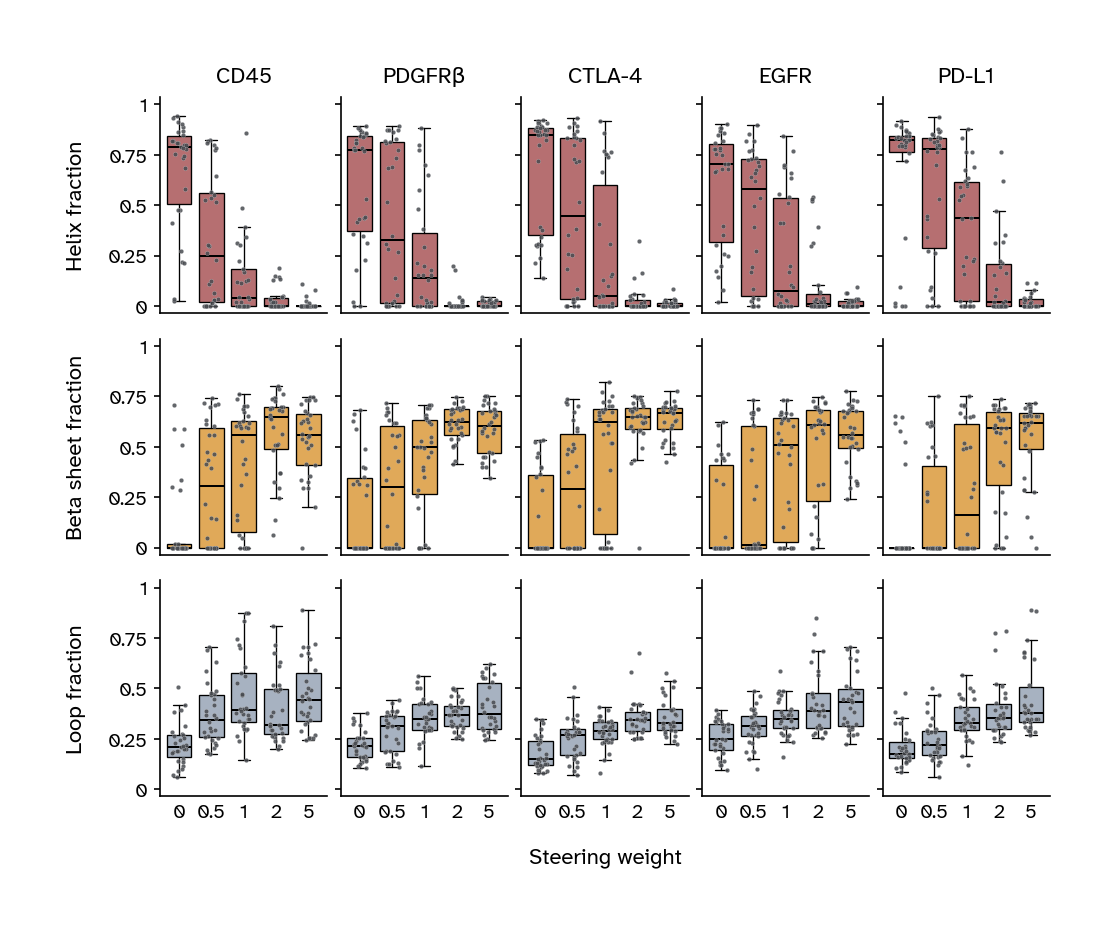

In [ ]:
# | label: fig-generality
# | fig-cap: "Final secondary-structure fractions across all five targets and steering weights (30 designs per target and weight), assigned by PyDSSP from the primary critic’s predicted binder structures. Rows show helix, sheet, and loop fractions; columns show targets, with shared axes. Points show individual designs with horizontal jitter; boxes span the interquartile range, central lines mark medians, and whiskers extend to the most extreme observations within 1.5 times the interquartile range. Zero denotes unsteered design. Conditions are equally spaced; spacing doesn't represent the numerical difference between weights."
# | out-width: "100%"
# | code-fold: true
# | code-summary: "Compare compositions by target, ordered by median helicity at weight 0.5"

TARGET_ORDER = (
    steered[steered["arm"] == "helix_mean_w05"]
    .groupby("target")["helix (fraction 0-1)"]
    .median()
    .sort_values()
    .index.tolist()
)
figures.scan_boxplots(steered, TARGET_ORDER, ARMS, ("helix", "sheet", "loop"))
plt.show()

Median helix decreased with weight on all five targets. Some targets, such as CD45, responded more strongly to intermediate weights than others, such as PD-L1. All reached a median helix fraction of zero by weight 5.0. β-sheet and loop proportions increased as helix decreased, yielding sheet-rich designs with substantial loop content. The broad distributions at intermediate weights show that the same steering weight can yield very different compositions across seeds.

### Steering lowers confidence

Steering produces more sheet-rich designs, but does it retain enough high-confidence candidates to make that change useful for a design campaign? We assessed confidence in the binder–target arrangement using the interface predicted template modeling score (ipTM), and confidence in local binder structure using the binder's predicted local distance difference test (pLDDT) score. @fig-cost and @tbl-cost show how confidence changes across the full population of designs.

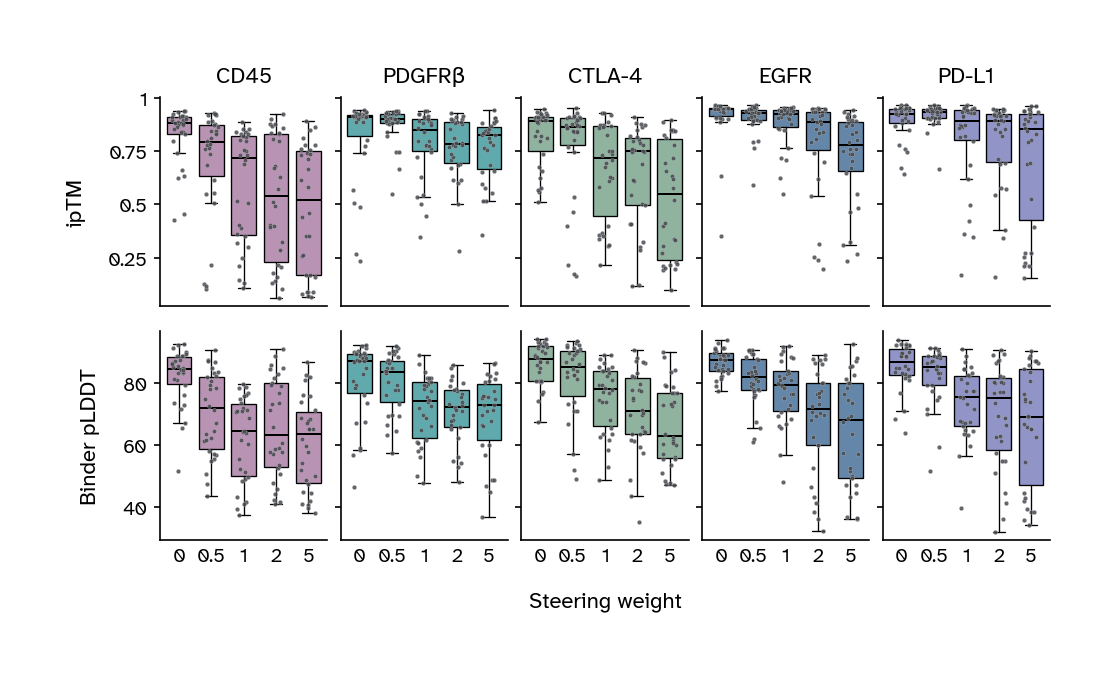

In [ ]:
# | label: fig-cost
# | fig-cap: "Interface predicted template modeling score (ipTM; top) and binder predicted local distance difference test (pLDDT) score (bottom), both from the primary critic, across steering weights, with 30 designs per target and weight. Columns use the same target order as @fig-generality. Points show individual designs with horizontal jitter; boxes span the interquartile range, central lines mark medians, and whiskers extend to the most extreme observations within 1.5 times the interquartile range. Box colors identify targets. Y-axis limits are shared within each row and span the observed values; neither row starts at zero. Zero on the x-axis denotes unsteered design. Conditions are equally spaced; spacing doesn't represent the numerical difference between weights."
# | out-width: "100%"
# | code-fold: true
# | code-summary: "Compare final confidence distributions by target and steering weight"

figures.scan_boxplots(steered, TARGET_ORDER, ARMS, ("iptm", "plddt"))
plt.show()

In [ ]:
# | label: tbl-cost
# | tbl-cap: "Median primary-critic ipTM and binder pLDDT by target and steering weight, each based on 30 designs. ipTM, interface predicted template modeling score (0–1); pLDDT, predicted local distance difference test score (0–100)."
# | code-fold: true
# | code-summary: "Calculate median confidence by target and steering weight"

from analysis import tables
from IPython.display import display

cost_metric_labels = {
    "iptm (0-1)": "ipTM",
    "binder pLDDT (0-100)": "Binder pLDDT",
}
cost_tables = {}
for column, label in cost_metric_labels.items():
    cost_tables[label] = (
        steered.groupby(["target", "arm"])[column]
        .median()
        .unstack("arm")
        .reindex(index=TARGET_ORDER, columns=ARMS)
    )

cost_table = pd.concat(cost_tables, names=["Metric", "Target"])
display(tables.confidence(cost_table))

Both confidence measures generally decline as steering increases, although the size of the decline depends on the target. EGFR and PD-L1 retain relatively high interface confidence, while CD45 shows a more pronounced reduction. Even at strong steering weights, some candidates retain high confidence scores. We therefore counted how many designs pass the confidence screen and how many also meet the sheet-content requirement.

To distinguish these outcomes, we applied two in silico screens (@tbl-screen-criteria). The quality screen uses pLDDT and ipTM thresholds. The combined screen additionally requires a predicted sheet fraction above 0.40. The table below shows the thresholds for both screens.

| Screen | Requirements |
|---|---|
| Quality | ipTM above 0.85 and binder pLDDT above 80 |
| Quality + sheet content | Quality criteria and sheet fraction above 0.40 |

: Criteria defining a candidate that passes each in silico screen. {#tbl-screen-criteria}

@tbl-sheet-screen reports the number of candidates passing each screen, so we can compare the loss of high-confidence candidates directly with the yield of candidates that also have the desired composition.

In [ ]:
# | label: tbl-sheet-screen
# | tbl-cap: "Candidates passing each in silico screen by target and steering weight. Each target has 30 designs per weight, for 150 designs per column. Pass rates use all designs at that weight as the denominator. Confidence scores and PyDSSP secondary structure come from the primary critic."
# | code-fold: true
# | code-summary: "Count candidates passing each screen"

quality_pass = (steered["iptm (0-1)"] > composition.MIN_IPTM) & (
    steered["binder pLDDT (0-100)"] > composition.MIN_BINDER_PLDDT
)
screens = {
    "Quality": quality_pass,
    "Quality + sheet content": quality_pass
    & (steered["sheet (fraction 0-1)"] > composition.MIN_SHEET_FRACTION),
}
screen_denominators = steered.groupby("arm").size().reindex(ARMS)
screen_tables = {}
for screen, passed in screens.items():
    counts = (
        steered.assign(passed=passed)
        .groupby(["target", "arm"])["passed"]
        .sum()
        .unstack("arm")
        .reindex(index=TARGET_ORDER, columns=ARMS)
    )
    counts.loc["Total"] = counts.sum()
    counts.loc["Pass rate"] = counts.loc["Total"] / screen_denominators
    screen_tables[screen] = counts

screen_table = pd.concat(screen_tables, names=["Screen", "Target"])
display(tables.screen_counts(screen_table))

Steering reduced the pooled number of candidates passing the quality screen, yet every tested steering weight yielded more candidates passing the combined screen than unsteered design. At weight 2.0, quality passes fell from 103 to 30, while passes for the combined screen rose from 15 to 29. Nearly all candidates that retained high confidence at this weight also met the sheet requirement. **Steering therefore produced a smaller pool of high-confidence candidates, enriched in the desired composition**.

Overall, steering away from ESMFold2's helix preference comes at the cost of lower in silico confidence. However, the biological meaning of that reduction remains unresolved. ESMFold2's confidence scores could be well calibrated, with β-sheet-rich designs scoring lower because they're less likely to fold and bind well. Alternatively, the scores could underestimate viable β-rich designs. The model's preference for generating α-helical designs (@fig-composition) motivates this possibility, but doesn't establish that its confidence scores are miscalibrated. Experimentally testing the designs could settle this.

## Helicity diverges while sequences remain soft

The final structures show how strongly steering changes composition, but not when those differences emerge during optimization. We tracked the helix proxy, interface-confidence proxy, and sequence entropy throughout optimization to see how the structural predictions develop as the soft sequence hardens (@fig-trace).

In [ ]:
# | code-fold: true
# | code-summary: "Calculate per-step medians across designs for each steering weight"

campaign_traces = {}
for target in TARGETS:
    for arm in ARMS:
        campaign_traces[target, arm] = loss_trace.load_campaign(target, arm)
trace = pd.concat(campaign_traces.values(), ignore_index=True)

trace_columns = {
    "helix_mean": "helix_mean (0-1)",
    "iptm_proxy": "distogram iptm proxy (0-1)",
    "entropy": "sequence entropy (bits)",
}
trace_medians = (
    trace.groupby(["arm", "step (index)"])[list(trace_columns.values())].median().reset_index()
)

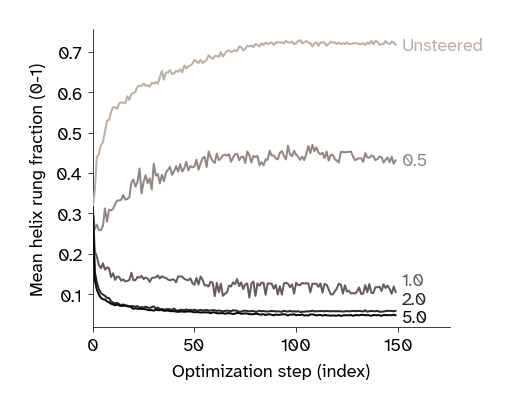

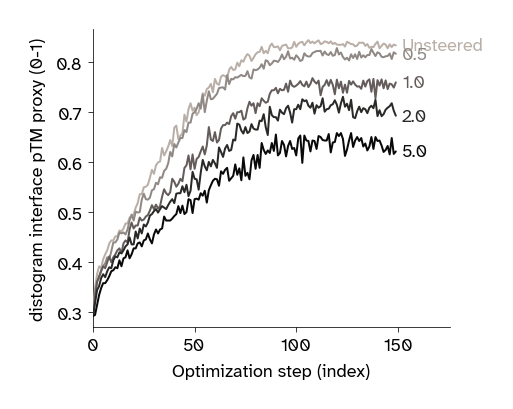

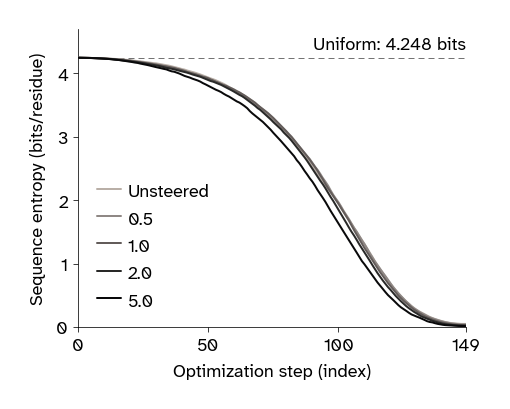

In [ ]:
# | label: fig-trace
# | fig-cap: "Median optimization diagnostics across 150 designs per condition, pooling five targets. The helix proxy is the mean predicted short-distance probability; the interface predicted template modeling score (ipTM) proxy is also computed from the distogram. Neither is the final primary-critic readout. Sequence entropy is the mean per-residue entropy of the soft amino-acid probabilities; the dashed line marks the uniform maximum over the 19 allowed amino acids (cysteine is excluded)."
# | fig-subcap:
# |   - "The loss term's own value"
# |   - "Distogram interface confidence proxy"
# |   - "Sequence entropy"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Plot median helicity, interface proxy, and sequence entropy during optimization"

from matplotlib import pyplot as plt

for metric in trace_columns:
    panel = figures.trace_summary(trace_medians, metric, ARMS)
    display(panel)
    plt.close(panel)

Helicity separated within the first few optimization steps. Without steering, it rose sharply. At a moderate weight of 0.5, it rose more slowly and plateaued earlier. At stronger weights, it fell below its initial value. By step 20, the pooled median ranged from 0.60 without steering to 0.06 at weight 5.0. Yet median sequence entropy remained between 4.19 and 4.21 bits per residue across all weights, barely below the uniform maximum of 4.25 bits per residue. The predictions had developed markedly different helicity even though the amino-acid distributions remained close to uniform.

:::{.callout-note collapse="true" title="Individual trajectories show the range of responses"}

The median trajectories in @fig-trace summarize runs with very different outcomes, even at the same steering weight. The 30 CD45 runs at weight 1.0 include both low- and high-helicity endpoints (@fig-seeds).

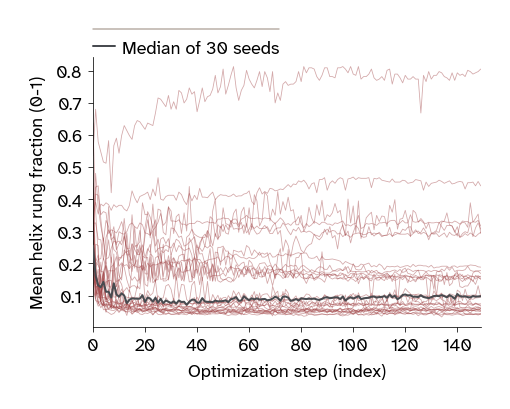

In [ ]:
# | label: fig-seeds
# | fig-cap: "Distogram helicity trajectories for all 30 CD45 runs at weight 1.0. Thin lines show individual seeds and the thick line shows their median. These values are the optimization proxy, not final PyDSSP helix fractions."
# | code-fold: true
# | code-summary: "Inspect individual CD45 trajectories and their final helicity proxies"

selected_traces = trace[(trace["target"] == "cd45_d3d4") & (trace["arm"] == "helix_mean_w10")]
final_proxy = selected_traces.loc[
    selected_traces["step (index)"] == targets.SGD_STEPS - 1, "helix_mean (0-1)"
]
panel = figures.seed_traces(selected_traces, "cd45_d3d4", "helix_mean_w10", "helix_mean")
display(panel)
plt.close(panel)

:::

## Takeaways

Adding a local distance penalty changes the predicted secondary-structure composition of ESMFold2 binder designs across five targets. Despite lower average confidence, steering increases the number of candidates meeting a sheet-content and confidence screen. Weight 2.0 gives the largest pooled count, while the most productive weight varies by target.

### What the experiments establish

An added objective can redirect the output of a pretrained binder-design workflow. Across five targets, increasing the helicity penalty shifts predicted structures toward sheet and loop, with lower confidence scores. Under the selected sheet and confidence criteria, weight 2.0 yields 29 candidates compared with 15 without steering (@tbl-sheet-screen). The per-target counts show why the choice of weight should also reflect the target.

Across five targets, helicity diverges under different steering weights while sequence entropy remains near its maximum. We report additional experiments on when loss steering must act in @sec-steering-timing.

Secondary-structure composition is one of many properties a design campaign might seek to control. Loss steering shows how changing an objective can customize ESMFold2's design procedure after training. Whether similar interventions can control other properties remains to be tested. The experimental usefulness and fold diversity of the resulting candidates remain open questions.

### The composition proxy leaves important properties unconstrained

A short-distance penalty can remove helices without specifying a complete alternative fold. It doesn't reward strand pairing, sheet closure, packing, or a particular binding interface. An optimizer can lower the penalty by producing extended or irregular structure, which is consistent with the increase in loop as well as sheet.

Secondary-structure fractions therefore need to be paired with structural inspection. A β-rich structure may be an open sheet with exposed edges, a compact sheet-containing fold, or a poorly packed arrangement. Our composition measurements don't quantify those alternatives, so they can't support a claim of increased fold diversity or improved developability.

### The biological meaning of lower confidence remains unresolved

Loss steering produces more β-rich candidates with lower average confidence than the unsteered baseline. These score changes leave the central biological question unresolved. The scores may correctly identify structures that fold or bind poorly. Alternatively, the model may assign lower confidence to viable β-rich designs because they fall outside the structural compositions it most readily generates.

The strong helical preference of the unsteered workflow makes this possibility worth investigating. It establishes a bias in the generated composition distribution, but doesn't establish whether confidence is miscalibrated: A preference during design and an inaccurate assessment of a finished design are different observations. The practical consequence is substantial. If lower scores reflect weaker binders, steering carries a biological cost; if they underestimate viable β-rich candidates, confidence filtering could discard useful designs.

We need to evaluate the steered candidates experimentally to determine what these score changes mean for binder design.

## Next steps

Our main next step is to test whether the β-rich candidates produced by loss steering are viable in the laboratory. We plan to evaluate whether these sequences yield folded proteins that bind their intended targets. This will establish whether expanding the predicted composition distribution also expands the pool of useful binders.

Those results will also help interpret the lower computational confidence of steered designs. The central question is whether the scores reflect a real loss of candidate quality, underestimate successful designs with different structural compositions, or capture some combination of the two.

## Appendix: Early steering has a lasting effect {#sec-steering-timing}

The trajectories show an early separation between steered and unsteered runs (@fig-trace). This raises two questions: Can a penalty introduced later still redirect composition, and can we withdraw early steering while preserving that change?

We tested these questions on PD-L1 with two parameter scans. For the *onset* scan, we varied the optimization step at which we first applied the helicity penalty, then kept it active for the rest of the run. For the *withdrawal* scan, we applied the penalty from the start and varied the step at which we removed it. Both scans used weight 2.0, which produced a strong composition response in @fig-trace. Each condition contains 30 designs, with 150 optimization steps per design (@fig-schedule).

:::{.callout-note title="Comparing steering schedules"}

Individual designs aren't seed-reproducible in this workflow. These campaigns therefore compare outcome distributions under different schedules, rather than tracking the same design with and without a change in timing.

:::

In [ ]:
# | code-fold: true
# | code-summary: "Measure onset and withdrawal campaigns, reusing the shared endpoints"

SCAN_TARGET = "pdl1_igv"
scans = {"onset": targets.ONSET_SCAN, "withdrawal": targets.RELEASE_SCAN}
schedule_arms = set(scans["onset"].values()) | set(scans["withdrawal"].values())
for arm in sorted(schedule_arms):
    key = (SCAN_TARGET, arm)
    if key not in campaign_composition:
        campaign_composition[key] = composition.measure_campaign(*key)
        campaign_traces[key] = loss_trace.load_campaign(*key)

schedule_designs, schedule_medians = {}, {}
for name, scan in scans.items():
    schedule_designs[name] = pd.concat(
        [campaign_composition[SCAN_TARGET, arm] for arm in scan.values()], ignore_index=True
    )
    scan_trace = pd.concat([campaign_traces[SCAN_TARGET, arm] for arm in scan.values()])
    schedule_medians[name] = (
        scan_trace.groupby(["arm", "step (index)"])[["helix_mean (0-1)"]].median().reset_index()
    )

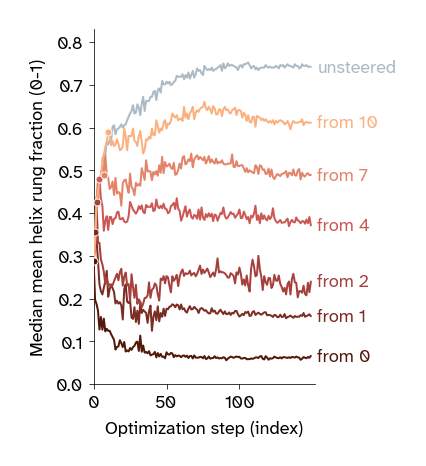

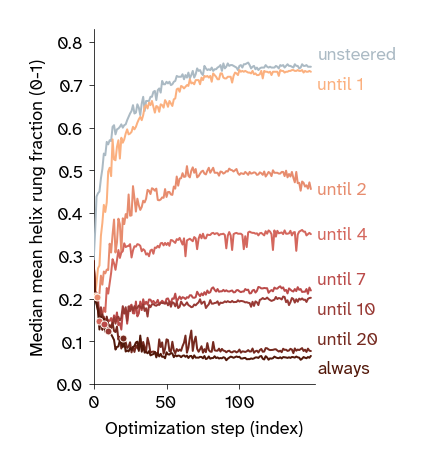

In [ ]:
# | label: fig-schedule
# | fig-cap: "Median distogram helicity during PD-L1 optimization with delayed or withdrawn steering (weight 2.0; 30 designs per condition; 150 steps). Labels mark when the penalty begins ('from') or ends ('until'); dots mark switching steps. The unsteered and continuously steered campaigns are shared controls. These traces show the optimization proxy; final sheet fractions in the text are measured separately with PyDSSP."
# | fig-subcap:
# |   - "Delaying the start of steering"
# |   - "Stopping steering early"
# | layout-ncol: 2
# | code-fold: true
# | code-summary: "Compare helicity trajectories under delayed and withdrawn steering"

from matplotlib import pyplot as plt

drawn_steps = {
    "onset": (targets.SGD_STEPS, 0, 1, 2, 4, 7, 10),
    "withdrawal": (0, 1, 2, 4, 7, 10, 20, targets.SGD_STEPS),
}
for panel in figures.schedule_trace_panels(schedule_medians, scans, drawn_steps):
    display(panel)
    plt.close(panel)

In [ ]:
# | code-fold: true
# | code-summary: "Calculate final sheet fractions separately from the optimization proxy"
# | output: false

schedule_sheet_medians = {}
for name, scan in scans.items():
    median_sheet = schedule_designs[name].groupby("arm")["sheet (fraction 0-1)"].median()
    schedule_sheet_medians[name] = pd.Series(
        {step: median_sheet[arm] for step, arm in scan.items()}, name="Median sheet fraction"
    )

Delaying steering until step 4 reduced median final sheet from 59% to less than 1%. Yet steering for only the first 20 steps left 55% median sheet after the remaining 130 steps without the penalty. Early steering therefore has a lasting effect on final composition.